# Assignment 2 — Regression on the Energy Efficiency Dataset
**Course:** Intro to Data Science (IT803A) · **Student:** _your name / Canvas ID_

**Goal:** predict a building's **Heating Load** and **Cooling Load** (kWh/m²) from 8 design features,
compare classical regression models with a neural network, track experiments with MLflow, and deploy the model.

Dataset: [UCI Energy Efficiency](https://archive.ics.uci.edu/dataset/242/energy+efficiency) — 768 buildings simulated
in Ecotect (12 base shapes × 4 orientations × glazing settings).

## Part 1 — Data Preparation & EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid", context="notebook")
HEAT, COOL, BLUE = "#eb6834", "#2a78d6", "#2a78d6"   # heating = orange, cooling = blue

df = pd.read_csv("data/energy_efficiency_data.csv")
TARGETS  = ["Heating_Load", "Cooling_Load"]
FEATURES = [c for c in df.columns if c not in TARGETS]
df.head()

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


### 1.1 Structure and summary statistics
First question in any EDA: *what does a row represent, what type is each column, and how many distinct values does it take?*
Low cardinality tells us which "numeric" columns are really categorical.

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (768, 10)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [3]:
pd.concat([df.describe().T.round(2), df.nunique().rename("n_unique")], axis=1)

,count,mean,std,min,25%,50%,75%,max,n_unique
Relative_Compactness,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98,12
Surface_Area,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50,12
Wall_Area,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50,7
Roof_Area,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50,4
Overall_Height,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00,2
Orientation,768.0,3.50,1.12,2.00,2.75,3.50,4.25,5.00,4
Glazing_Area,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40,4
Glazing_Area_Distribution,768.0,2.81,1.55,0.00,1.75,3.00,4.00,5.00,6
Heating_Load,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10,586
Cooling_Load,768.0,24.59,9.51,10.90,15.62,22.08,33.13,48.03,636


### 1.2 Missing values and duplicates

In [4]:
print("Missing values per column:\n", df.isna().sum(), sep="")
print("\nFully duplicated rows:", df.duplicated().sum())

Missing values per column:
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

Fully duplicated rows: 0


### 1.3 Distributions
Targets are continuous → histograms. Features are discrete design settings → value counts (bar charts) are more honest than histograms.

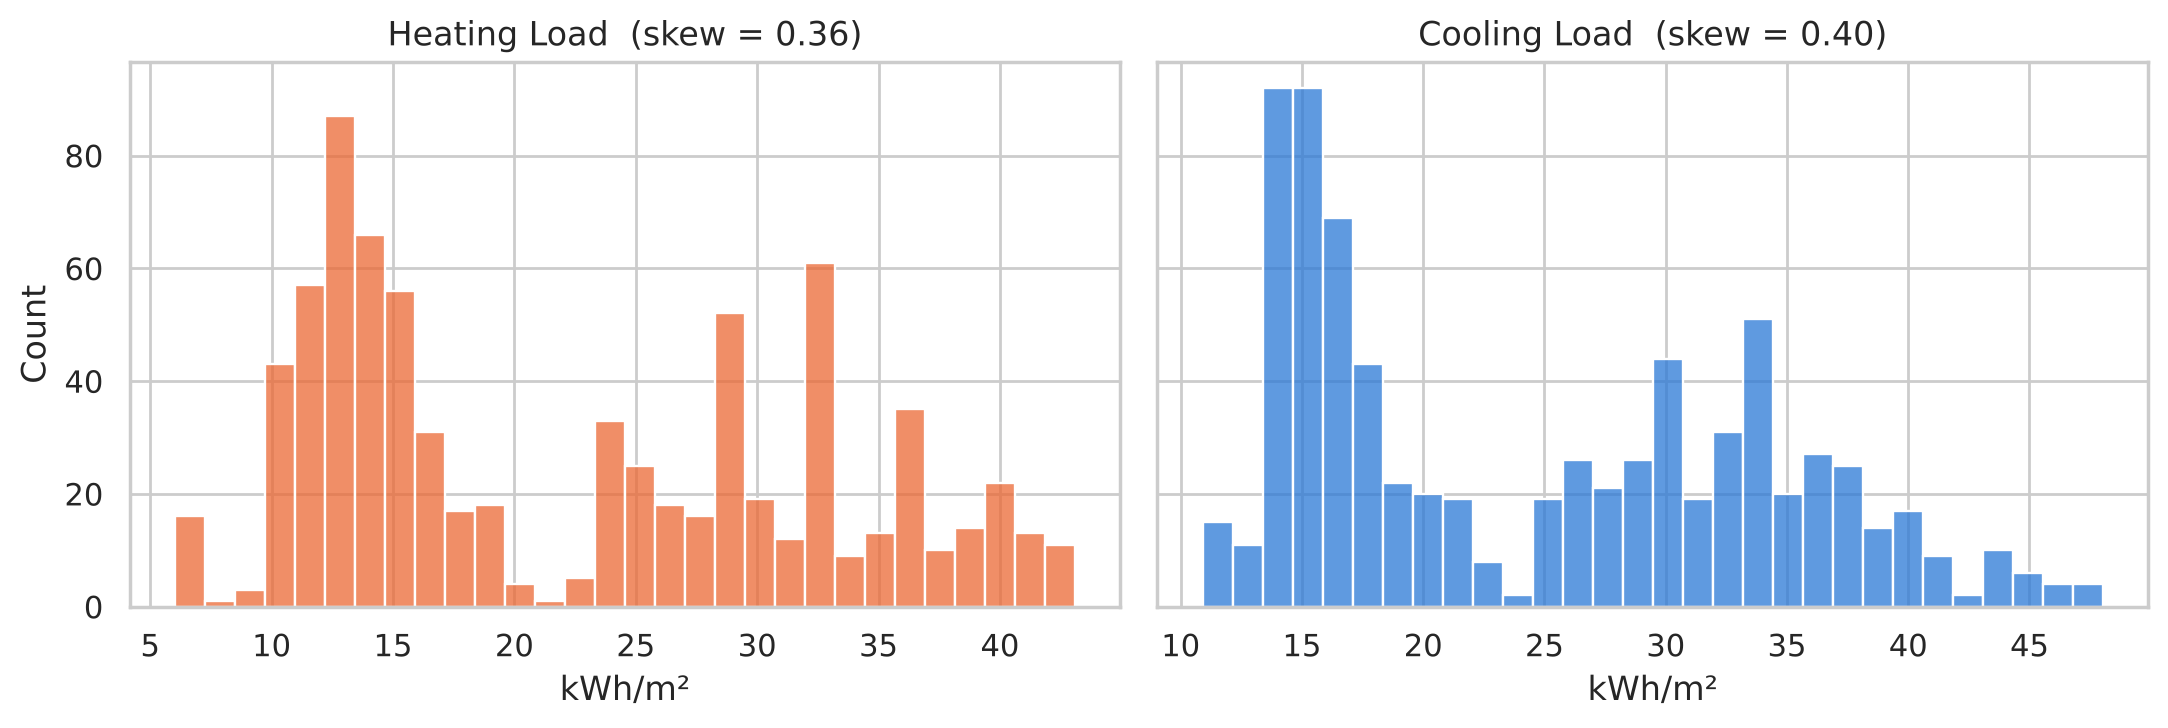

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, t, col in zip(axes, TARGETS, [HEAT, COOL]):
    sns.histplot(df[t], bins=30, color=col, ax=ax, edgecolor="white")
    ax.set_title(f"{t.replace('_', ' ')}  (skew = {df[t].skew():.2f})")
    ax.set_xlabel("kWh/m²")
plt.tight_layout(); plt.show()

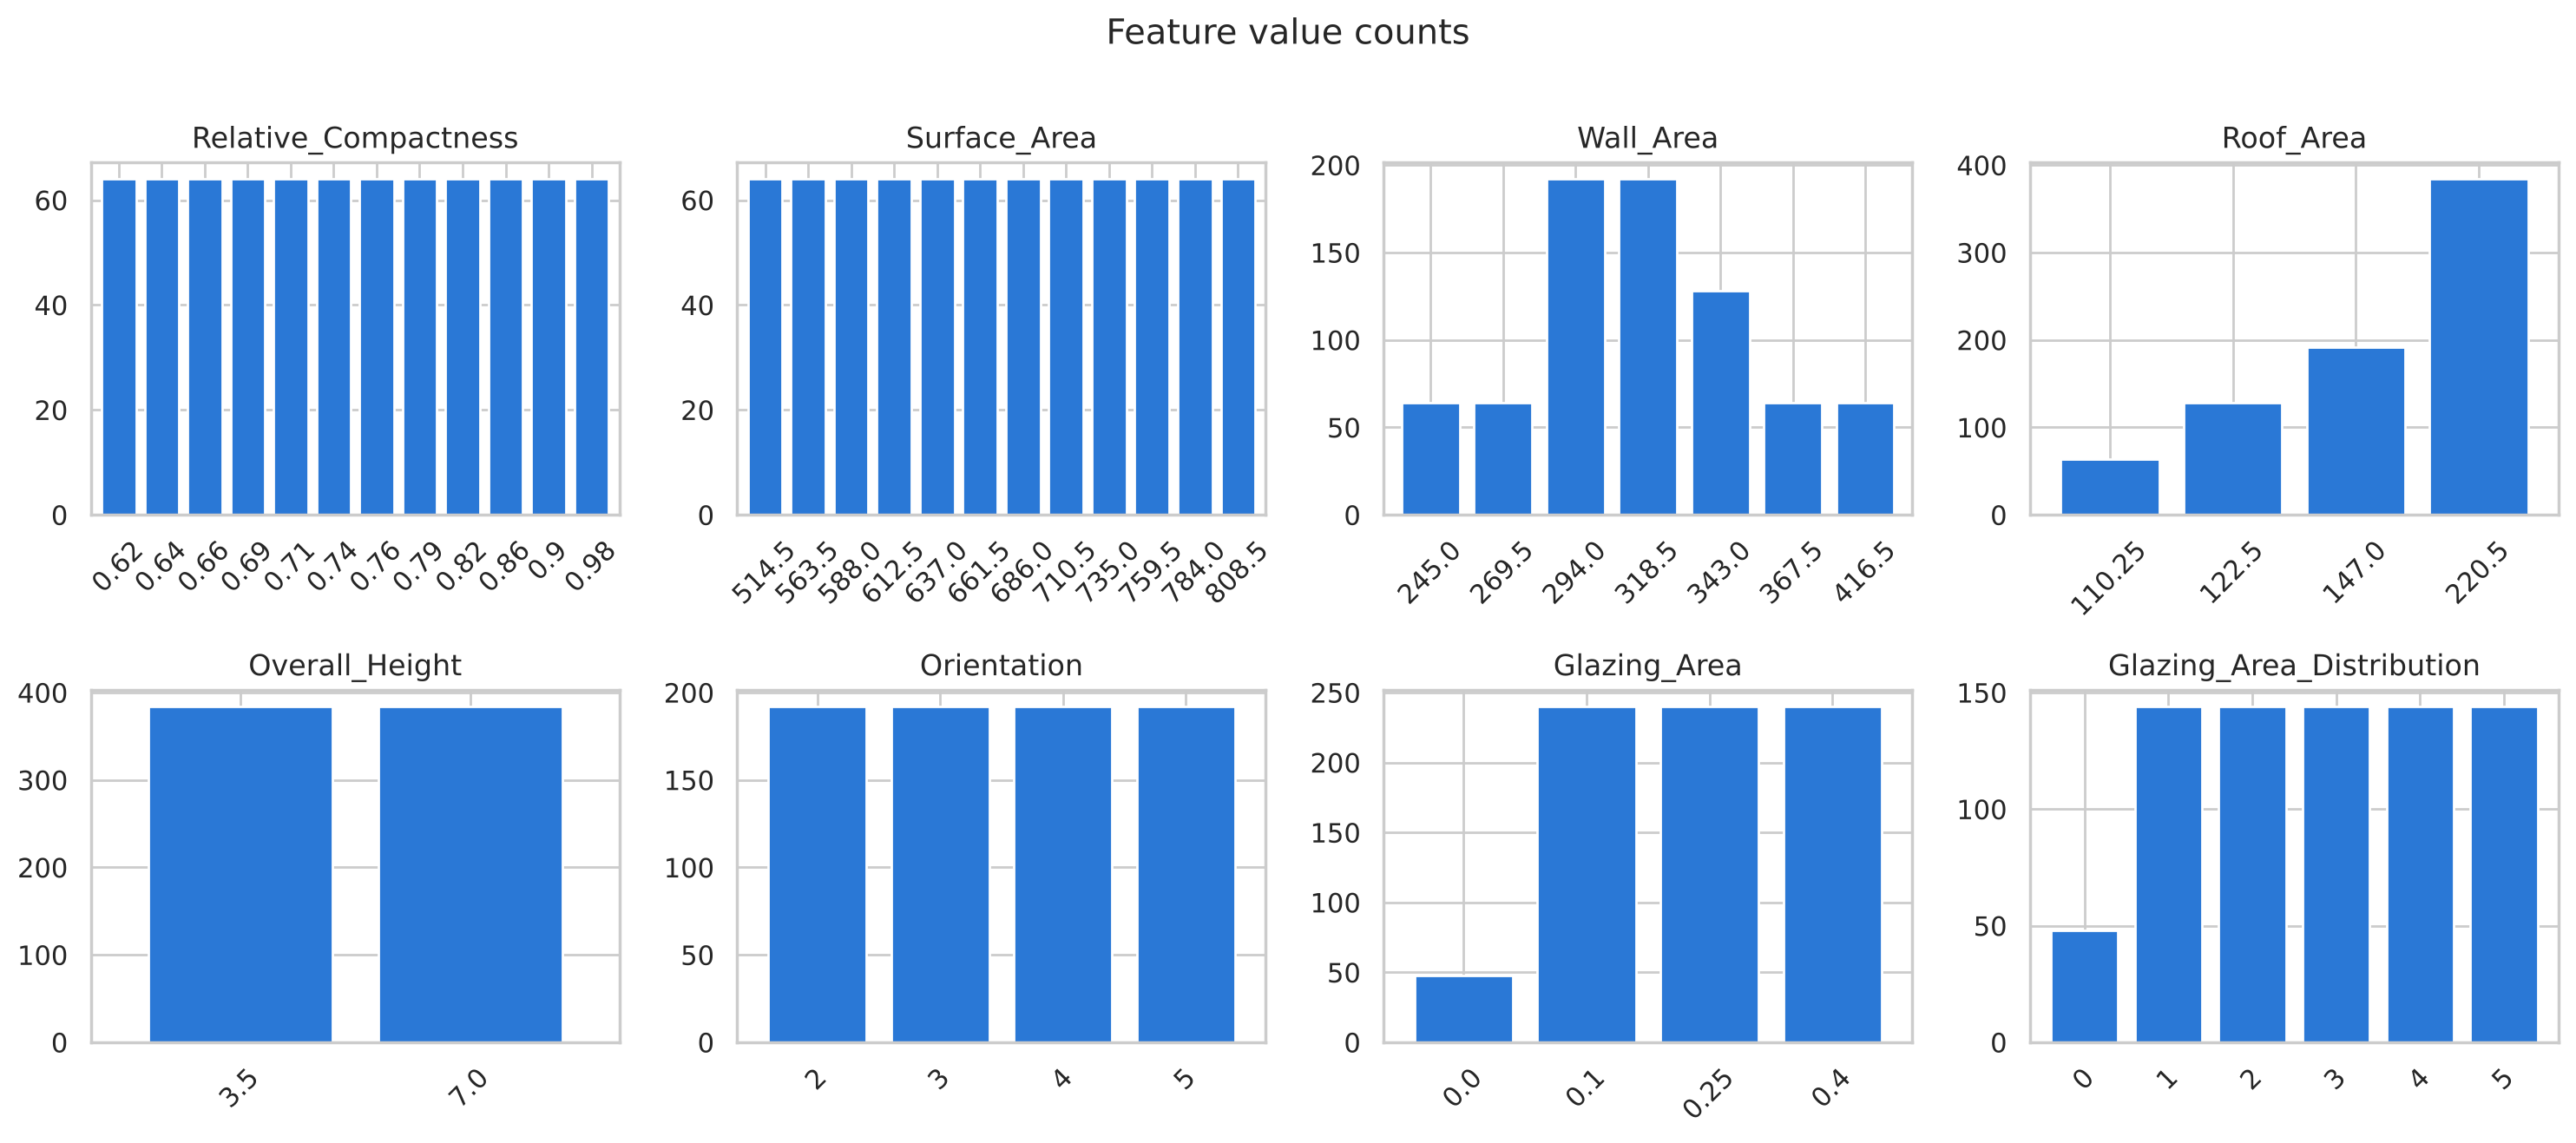

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, f in zip(axes.flat, FEATURES):
    df[f].value_counts().sort_index().plot.bar(ax=ax, color=BLUE, edgecolor="white", width=0.8)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.suptitle("Feature value counts", y=1.01); plt.tight_layout(); plt.show()

### 1.4 Outliers
Two complementary checks:
1. **Global (IQR rule):** values beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR.
2. **Contextual:** rows sharing the same design (identical features except orientation) should have almost identical loads,
   so a large deviation from the *group median* flags a suspicious value that a global rule would miss.

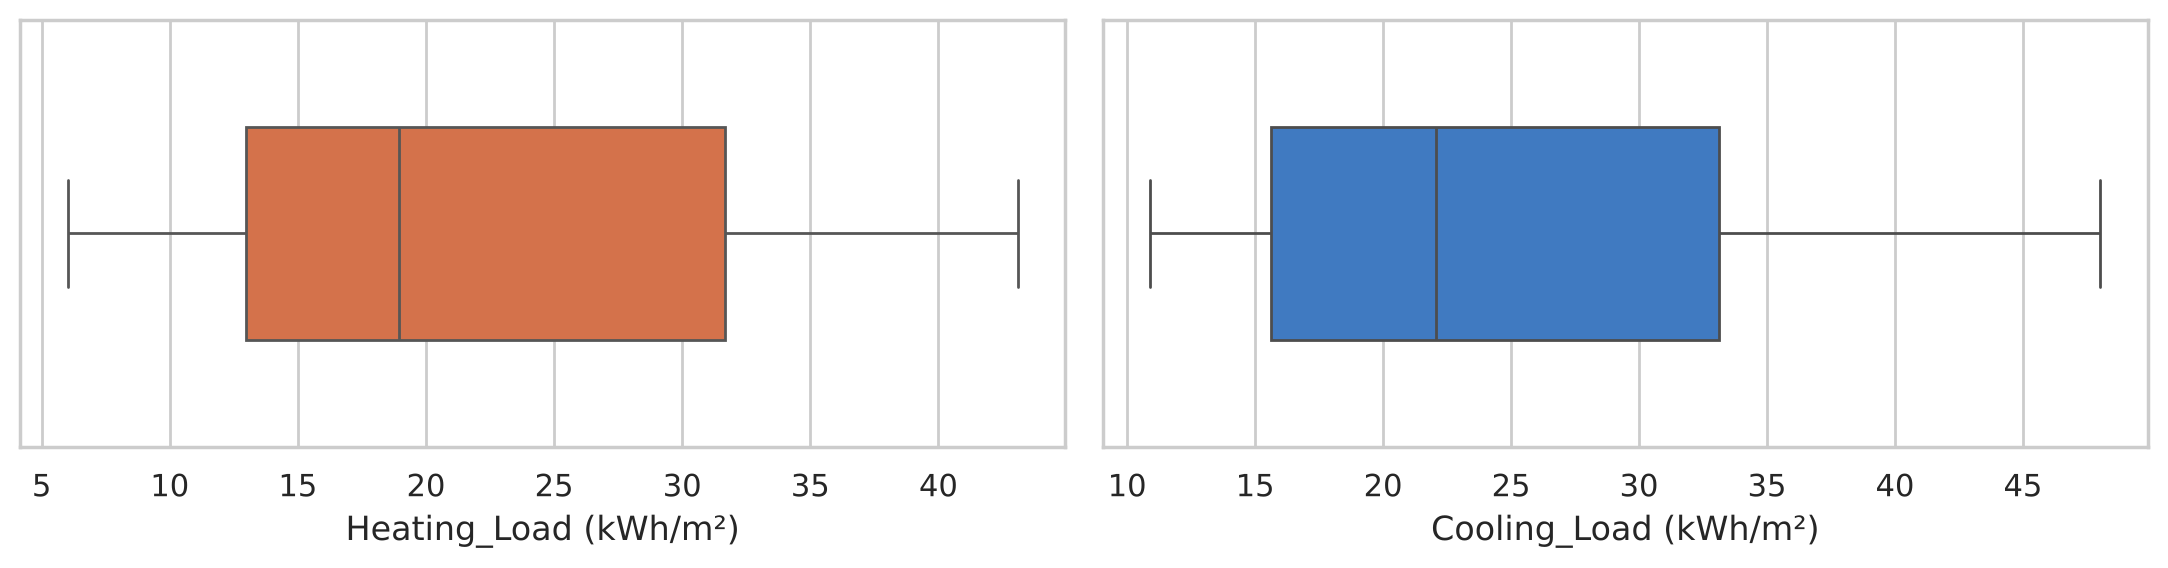

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
IQR outliers,0,0,0,0,0,0,0,0,0,0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, t, col in zip(axes, TARGETS, [HEAT, COOL]):
    sns.boxplot(x=df[t], color=col, ax=ax, width=0.5); ax.set_xlabel(f"{t} (kWh/m²)")
plt.tight_layout(); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

df.apply(iqr_outliers).rename("IQR outliers").to_frame().T

In [8]:
design_cols = [c for c in FEATURES if c != "Orientation"]
dev = df[["Heating_Load"]].copy()
dev["group_median"] = df.groupby(design_cols)["Heating_Load"].transform("median")
dev["abs_deviation"] = (df["Heating_Load"] - dev["group_median"]).abs()
pd.concat([df[design_cols + ["Orientation"]], dev], axis=1).sort_values("abs_deviation", ascending=False).head(5).round(2)

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Glazing_Area_Distribution,Orientation,Heating_Load,group_median,abs_deviation
271,0.71,710.5,269.5,220.5,3.5,0.1,5,5,13.69,10.74,2.95
572,0.62,808.5,367.5,220.5,3.5,0.4,1,2,15.09,17.14,2.05
259,0.79,637.0,343.0,147.0,7.0,0.1,5,5,35.48,36.74,1.26
11,0.86,588.0,294.0,147.0,7.0,0.0,0,5,18.31,19.42,1.11
7,0.90,563.5,318.5,122.5,7.0,0.0,0,5,19.68,20.78,1.09


### 1.5 Relationships between features and targets

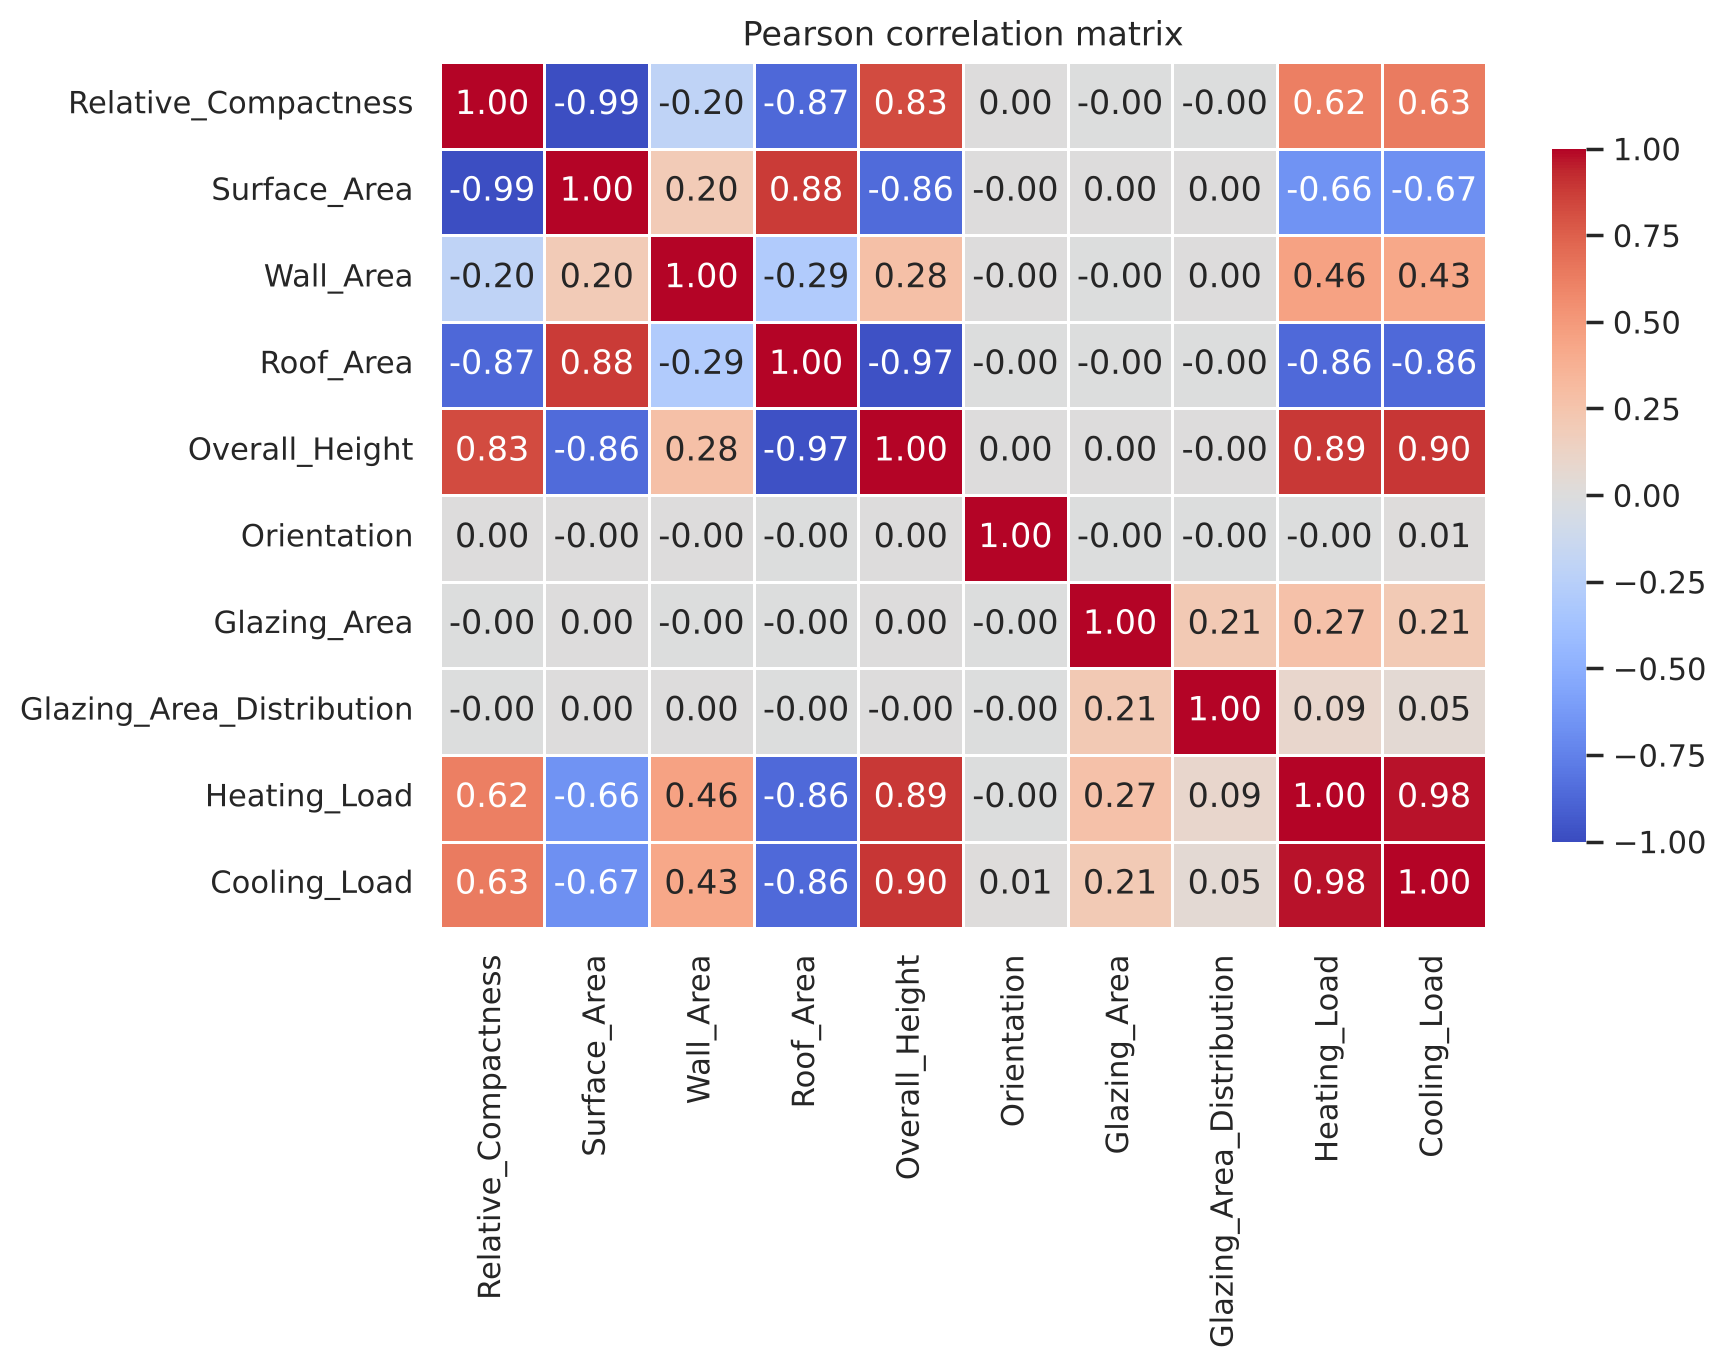

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson correlation matrix"); plt.tight_layout(); plt.show()

Because each feature takes only a few values, the clearest view of each relationship is the **mean load at every feature value**
(error bars = 95% CI). Both targets share the same unit, so they go on one axis.

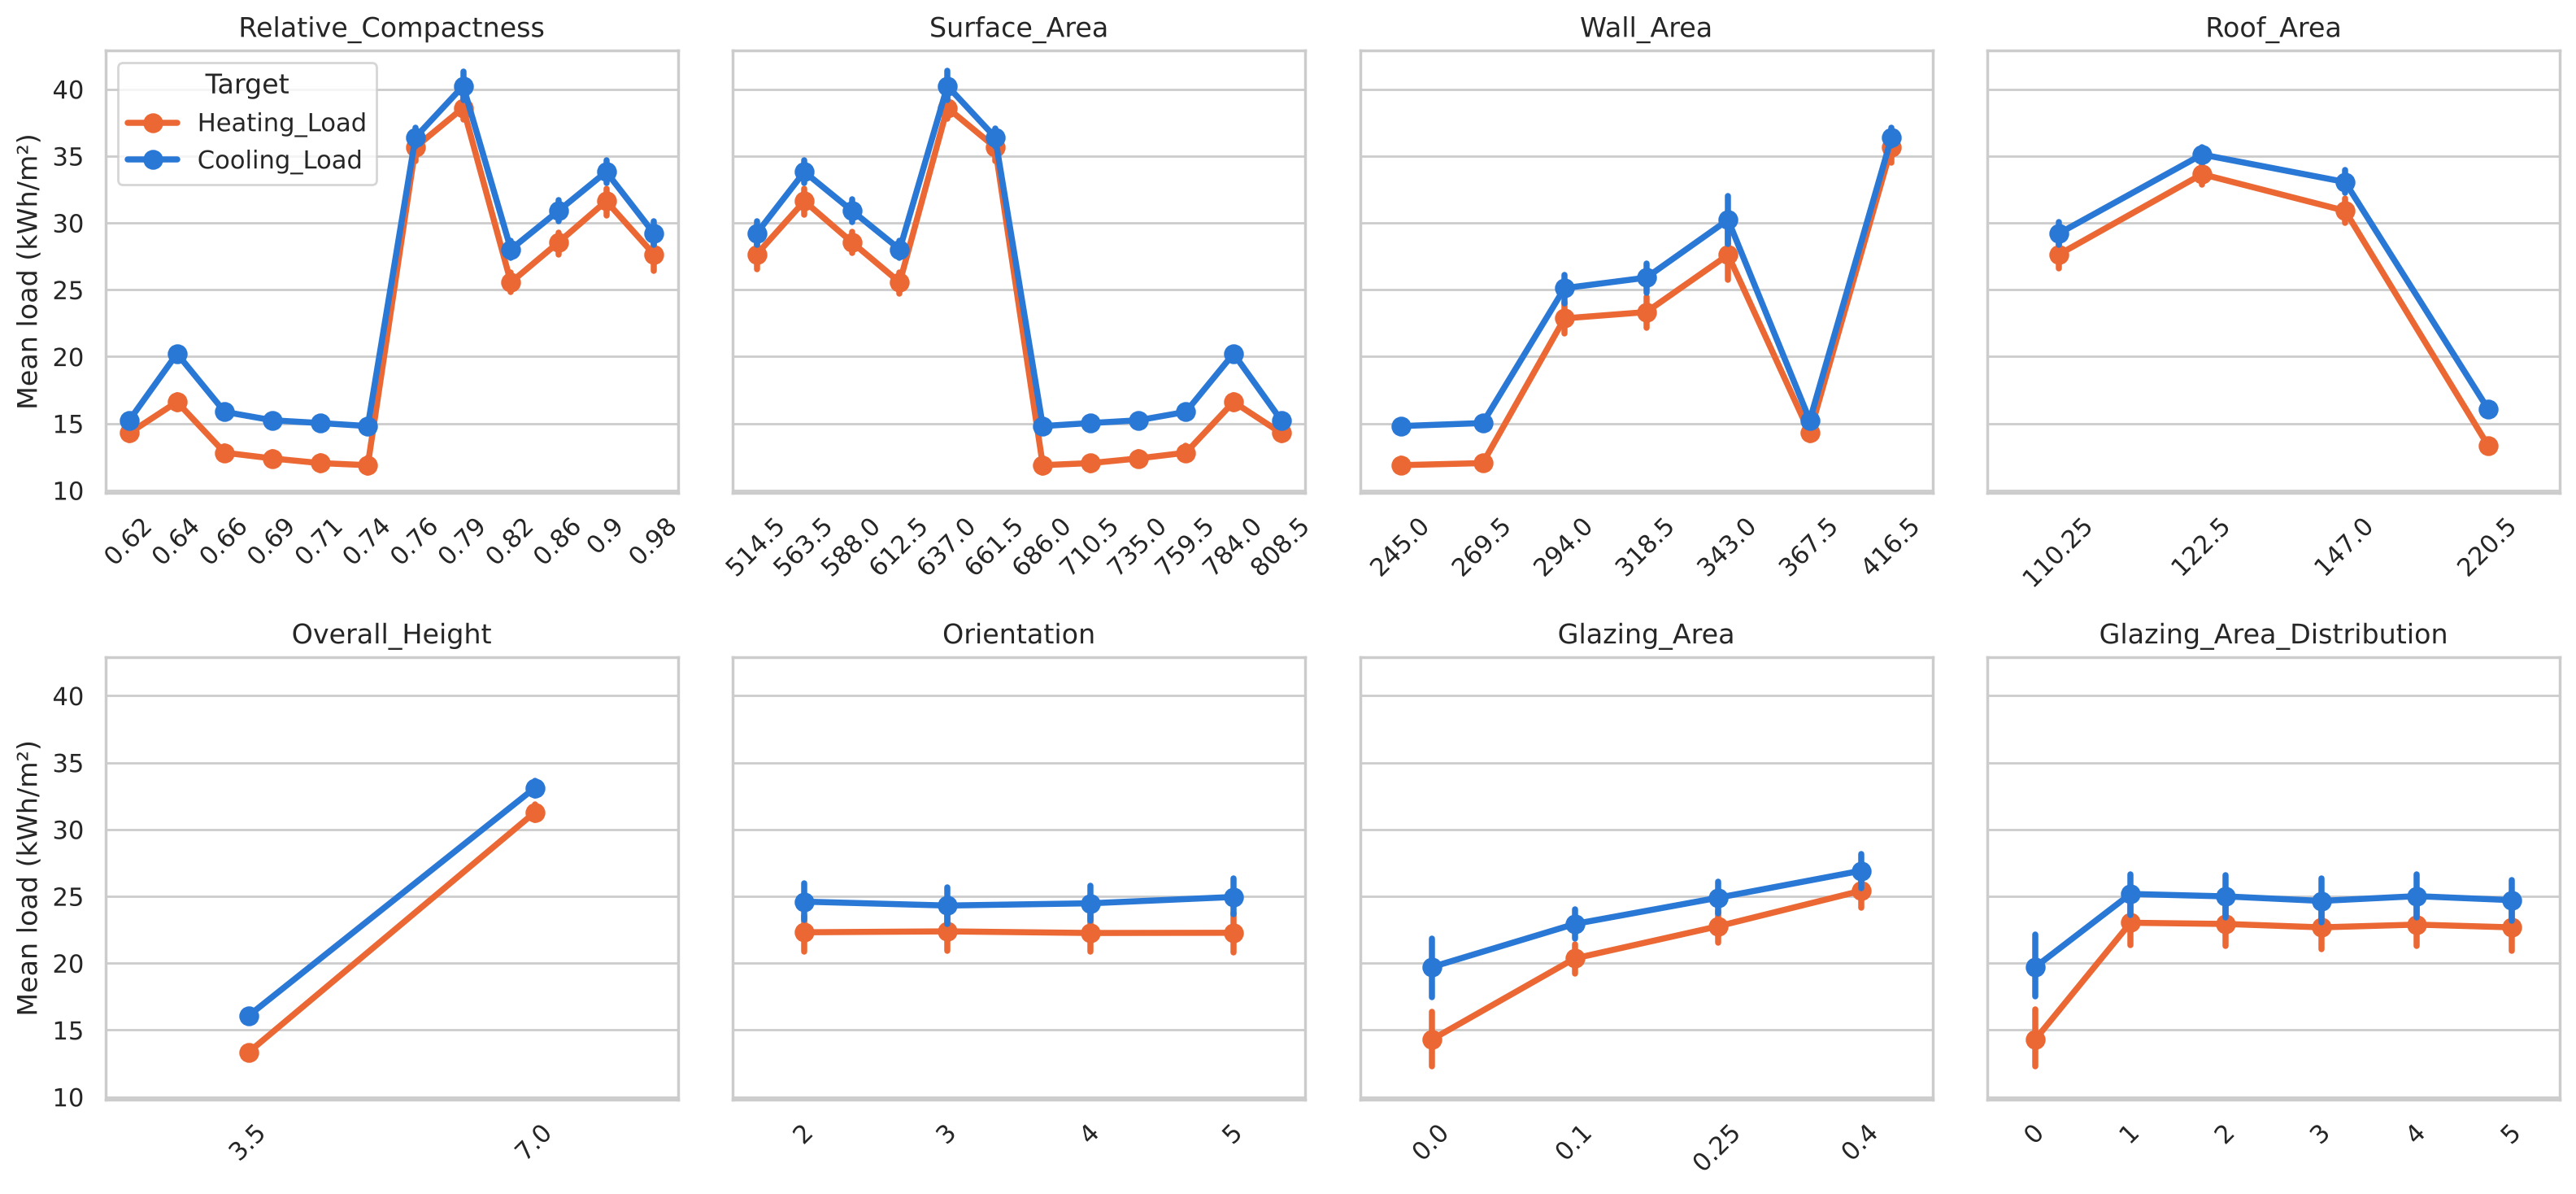

In [10]:
long = df.melt(id_vars=FEATURES, value_vars=TARGETS, var_name="Target", value_name="Load")
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), sharey=True)
for ax, f in zip(axes.flat, FEATURES):
    sns.pointplot(data=long, x=f, y="Load", hue="Target", palette=[HEAT, COOL],
                  errorbar=("ci", 95), markers="o", linestyles="-", ax=ax, legend=(f == FEATURES[0]))
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("Mean load (kWh/m²)"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Why does Relative Compactness correlate *positively* with load?** Physically, a more compact building loses less heat.
Splitting by height shows what's going on.

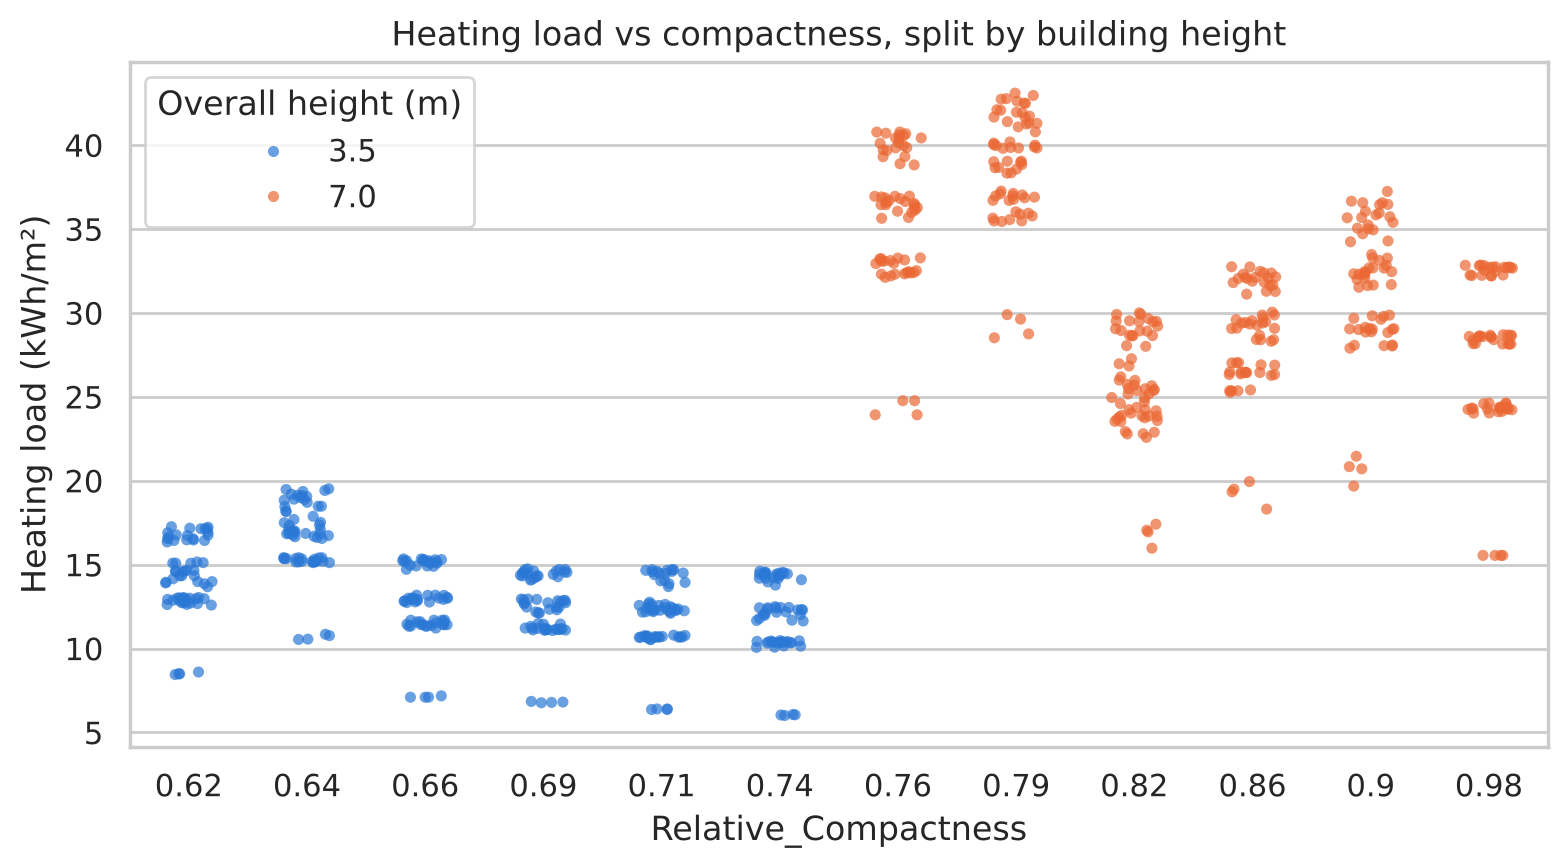

Correlation (Relative_Compactness vs Heating_Load)
  overall       : 0.62
  height = 3.5 m : -0.48
  height = 7.0 m : -0.44


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.stripplot(data=df, x="Relative_Compactness", y="Heating_Load", hue="Overall_Height",
              palette=[BLUE, HEAT], jitter=0.2, size=4, alpha=0.7, ax=ax)
ax.set_ylabel("Heating load (kWh/m²)"); ax.legend(title="Overall height (m)")
ax.set_title("Heating load vs compactness, split by building height")
plt.tight_layout(); plt.show()

print("Correlation (Relative_Compactness vs Heating_Load)")
print("  overall       :", round(df["Relative_Compactness"].corr(df["Heating_Load"]), 2))
for h, d in df.groupby("Overall_Height"):
    print(f"  height = {h} m :", round(d["Relative_Compactness"].corr(d["Heating_Load"]), 2))

**Is `Orientation` useless?** Its correlation with both targets is about 0 and its average effect is flat.
But correlation only measures a *linear, average* effect. Below, for each building design (all features fixed except orientation),
we measure how much the load changes when only the orientation changes.

In [12]:
design_cols = [c for c in FEATURES if c != "Orientation"]
orient_range = (df.groupby(design_cols)[TARGETS].agg(lambda s: s.max() - s.min())
                  .groupby("Relative_Compactness").mean().round(2))
orient_range.columns = ["Heating range from orientation", "Cooling range from orientation"]
orient_range

,Heating range from orientation,Cooling range from orientation
Relative_Compactness,,
0.62,0.39,0.45
0.64,0.27,0.39
0.66,0.17,0.43
0.69,0.23,0.61
0.71,0.37,0.66
0.74,0.21,0.51
0.76,0.83,0.95
0.79,1.48,8.86
0.82,1.23,3.77


### 1.6 Multicollinearity
**Variance Inflation Factor:** regress each feature on all the others; VIF = 1 / (1 − R²).
VIF > 10 means that feature is mostly explained by the others, so linear-model coefficients become unstable.

In [13]:
def vif_table(data, cols):
    out = {}
    for c in cols:
        others = [o for o in cols if o != c]
        r2 = LinearRegression().fit(data[others], data[c]).score(data[others], data[c])
        out[c] = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out, name="VIF").round(1)

print("Surface_Area == Wall_Area + 2 * Roof_Area for every row:",
      np.allclose(df["Surface_Area"], df["Wall_Area"] + 2 * df["Roof_Area"]))

pd.concat([vif_table(df, FEATURES).rename("VIF (all 8)"),
           vif_table(df, [f for f in FEATURES if f != "Surface_Area"]).rename("VIF (without Surface_Area)")], axis=1)

Surface_Area == Wall_Area + 2 * Roof_Area for every row: True


,VIF (all 8),VIF (without Surface_Area)
Relative_Compactness,105.5,105.5
Surface_Area,inf,NaN
Wall_Area,inf,27.7
Roof_Area,inf,211.9
Overall_Height,31.2,31.2
Orientation,1.0,1.0
Glazing_Area,1.0,1.0
Glazing_Area_Distribution,1.0,1.0


### 1.7 Feature selection & transformation
Decisions (justified by 1.3–1.6):
- **Drop `Surface_Area`**: it's an exact linear combination of `Wall_Area` and `Roof_Area` (infinite VIF), so it adds no information.
- **Keep `Roof_Area` and `Relative_Compactness` despite high VIF**: they are not *exact* duplicates, and Part 2 uses Ridge/Lasso, which are designed to handle correlated features.
- **Keep `Orientation`**: it has no average effect, but it changes cooling load by several kWh/m² for some shapes (an interaction a neural network can learn).
- **One-hot encode `Orientation` and `Glazing_Area_Distribution`**: they're category codes, not quantities.
- **No target transformation**: skew is about 0.4 and the two peaks come from building height, not from a long tail.
- **Scaling** (StandardScaler) is done *after* the train/test split in Part 2, fitting on the training set only, to avoid data leakage.

In [14]:
X = df.drop(columns=TARGETS + ["Surface_Area"])
X = pd.get_dummies(X, columns=["Orientation", "Glazing_Area_Distribution"], drop_first=True, dtype=int)
y = df[TARGETS]
print("X:", X.shape, "| y:", y.shape)
X.head()

X: (768, 13) | y: (768, 2)


,Relative_Compactness,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Orientation_3,Orientation_4,Orientation_5,Glazing_Area_Distribution_1,Glazing_Area_Distribution_2,Glazing_Area_Distribution_3,Glazing_Area_Distribution_4,Glazing_Area_Distribution_5
0,0.98,294.0,110.25,7.0,0.0,0,0,0,0,0,0,0,0
1,0.98,294.0,110.25,7.0,0.0,1,0,0,0,0,0,0,0
2,0.98,294.0,110.25,7.0,0.0,0,1,0,0,0,0,0,0
3,0.98,294.0,110.25,7.0,0.0,0,0,1,0,0,0,0,0
4,0.90,318.5,122.50,7.0,0.0,0,0,0,0,0,0,0,0
